In [1]:
# 실습 준비 ① 설치 — Colab 에서만 설치합니다
#  새로 설치하는 것은 하나입니다 — 교안의 수를 계산한 버전에 맞춰 고정합니다.
#    kiwipiepy 0.23.1 : 한국어 형태소 분석기 Kiwi. 버전을 올리면 명사 목록이 조금 달라질 수 있습니다
#  sentence-transformers · transformers · torch · pandas · numpy · matplotlib 은 Colab 기본 버전을 그대로 씁니다.
#  교안의 수는 sentence-transformers 5.3.0 · transformers 5.3.0 · torch 2.11.0 에서 계산했습니다(아래 셀이 지금 버전을 출력합니다).
#  그래프의 한글을 위해 나눔 폰트도 여기서 설치합니다.
import shutil
import subprocess
import sys

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kiwipiepy==0.23.1"], check=False)
    if shutil.which("apt-get"):
        subprocess.run(["apt-get", "-y", "-qq", "install", "fonts-nanum"], check=False)
print("설치 셀 완료 —", "kiwipiepy 0.23.1 · 나눔 폰트를 설치했습니다" if IN_COLAB
      else "Colab 이 아니라 설치를 건너뛰었습니다(kiwipiepy · sentence-transformers 가 이미 있어야 합니다)")

설치 셀 완료 — Colab 이 아니라 설치를 건너뛰었습니다(kiwipiepy · sentence-transformers 가 이미 있어야 합니다)


In [2]:
# 실습 준비 ② 환경 확인 — 한글 폰트 · 그림 색 · DEVICE · 문장 인코더 설정 · 버전
import glob
import os
import sys
import warnings

import matplotlib.font_manager as fm
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

# 한글 폰트 — 설치한 나눔 ttf 를 폰트 목록에 직접 등록합니다.
#  설치는 디스크에 파일만 만듭니다. 이미 불러온 폰트 목록에는 새 파일이 들어 있지 않으므로 addfont 로
#  등록해야 이름이 보입니다(등록하지 않으면 DejaVu Sans 로 바뀌어 한글이 전부 □ 로 나옵니다).
for _p in glob.glob("/usr/share/fonts/truetype/nanum/Nanum*.ttf"):
    try: fm.fontManager.addfont(_p)
    except Exception: pass
try: fm._get_font.cache_clear()
except Exception: pass
installed = {f.name for f in fm.fontManager.ttflist}
FONT = next((n for n in ["Pretendard", "Apple SD Gothic Neo", "NanumGothic"] if n in installed), "DejaVu Sans")
plt.rcParams["font.family"] = FONT
plt.rcParams["axes.unicode_minus"] = FONT in {"Pretendard", "DejaVu Sans"}   # 나머지 폰트에는 U+2212 가 없습니다
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}   # 그림마다 폭이 깎이지 않게
plt.rcParams["figure.dpi"] = plt.rcParams["savefig.dpi"] = 150       # 폭 FIG_W x 150dpi = 1500px 고정
plt.rcParams["figure.autolayout"] = True
plt.rcParams.update({"font.size": 11, "axes.titlesize": 15, "axes.labelsize": 12,
                     "legend.fontsize": 11, "figure.titlesize": 17, "font.weight": "regular",
                     "text.color": "black", "axes.labelcolor": "black", "axes.titlecolor": "black",
                     "axes.edgecolor": "#757575", "xtick.color": "#757575", "ytick.color": "#757575",
                     "xtick.labelcolor": "black", "ytick.labelcolor": "black",
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": False})

# 이 실습의 그림 전체가 함께 쓰는 색 — 기준 = 남색, 강조 = 하늘색, 문맥 = 회색
COL = {"남색": "#051C2C", "파랑": "#2251FF", "하늘색": "#00A9F4",
       "회색": "#757575", "연회색": "#B3B3B3"}
FIG_W = 10.0     # 캔버스 폭은 이 실습의 그림 모두 이 값으로 고정하고 높이만 그림마다 조절합니다

# DEVICE — 이 실습은 문장 인코더를 실행하므로 GPU 런타임을 권합니다
import torch
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if DEVICE == "cuda":
    _gpu = torch.cuda.get_device_properties(0)
    print(f"GPU : {_gpu.name} · 메모리 {_gpu.total_memory / 1024 ** 3:.1f}GB")
else:
    print("GPU 가 없습니다 — 작은 문장 인코더와 항공 민원 4,000건으로 같은 코드를 실행합니다")

# 문장 인코더 설정 — DEVICE 에 따라 정해집니다. 버전(revision)을 고정해 교안의 수를 계산한 가중치를 불러옵니다
#  GPU : nlpai-lab/KURE-v1 (MIT) — 접두어 없음, 항공 민원 12,232건 전체, 리뷰 3,000건
#  CPU : intfloat/multilingual-e5-small (MIT) — 접두어 「query: 」, 항공 민원 4,000건(시드 0), 리뷰 1,000건
if DEVICE == "cuda":
    MODEL_NAME, MODEL_REV, PREFIX = "nlpai-lab/KURE-v1", "8b418a58414668e75532ed045c22d9ca018ae2b2", ""
    N_AIR, N_REV = None, 3000
else:
    MODEL_NAME, MODEL_REV, PREFIX = "intfloat/multilingual-e5-small", "614241f622f53c4eeff9890bdc4f31cfecc418b3", "query: "
    N_AIR, N_REV = 4000, 1000
print(f"DEVICE : {DEVICE} · 문장 인코더 : {MODEL_NAME} · "
      + ("항공 민원 12,232건 전체" if N_AIR is None else f"항공 민원 {N_AIR:,}건(시드 0)")
      + f" · 리뷰 {N_REV:,}건 | 사용 폰트 : {FONT}")

import kiwipiepy
import sentence_transformers
import transformers
print(f"kiwipiepy {kiwipiepy.__version__} · sentence-transformers {sentence_transformers.__version__}"
      f" · transformers {transformers.__version__} · torch {torch.__version__.split('+')[0]}")
if kiwipiepy.__version__ != "0.23.1":
    print("참고 — 교안의 수는 kiwipiepy 0.23.1 로 계산했습니다. 다른 버전에서는 명사 목록이 조금 다를 수 있습니다.")

GPU 가 없습니다 — 작은 문장 인코더와 항공 민원 4,000건으로 같은 코드를 실행합니다
DEVICE : cpu · 문장 인코더 : intfloat/multilingual-e5-small · 항공 민원 4,000건(시드 0) · 리뷰 1,000건 | 사용 폰트 : DejaVu Sans
kiwipiepy 0.24.0 · sentence-transformers 6.2.0 · transformers 5.19.0 · torch 2.14.1
참고 — 교안의 수는 kiwipiepy 0.23.1 로 계산했습니다. 다른 버전에서는 명사 목록이 조금 다를 수 있습니다.


In [4]:
# ===== 한글 폰트 설정 =====
font_path = "C:/Windows/Fonts/malgun.ttf"
fm.fontManager.addfont(font_path)
plt.rcParams["font.family"] = fm.FontProperties(fname=font_path).get_name()
plt.rcParams["axes.unicode_minus"] = False

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 2292.37it/s]


문장 인코더 multilingual-e5-small · 항공 민원 4,000건 · 표준답변 1,332개 · 35초

표 1 · 항공 민원마다 가장 가까운 표준답변의 코사인 (백분위수)
  25백분위수 0.878 · 중앙값 0.885 · 75백분위수 0.893
  가장 작은 값 0.798 · 가장 큰 값 0.930

표 2 · 임계값을 중앙값에서 0.02 씩 옮길 때 대응 없는 항공 민원 (%)
  중앙값 − 0.02  임계값 0.865  →   4.9 %
  중앙값        임계값 0.885  →  50.0 %
  중앙값 + 0.02  임계값 0.905  →  94.1 %

표 3 · 후보 쌍 40개에서 가장 가까운 답으로 많이 나온 표준답변 (쌍)
  1230 · 청약철회_미성년자 계약 · 10쌍
     질문 「미성년자인 자녀가 부모의 동의 없이 신용카드로 국제선 항공권을 구매한 사…」
     이 답을 받은 민원 「출국 항공기 결항에 입국 항공권 해지에 취소수수료 청구 부당」
  1234 · 계약불이행_일방적인 항공편 취소 · 9쌍
     질문 「인천-비엔나 왕복 항공권을 구입한 후 귀국 시 비엔나→인천 편도 항공편이…」
     이 답을 받은 민원 「최근 유행하는 신종 코로나 바이러스 문제로 진에어 항공권 취소」


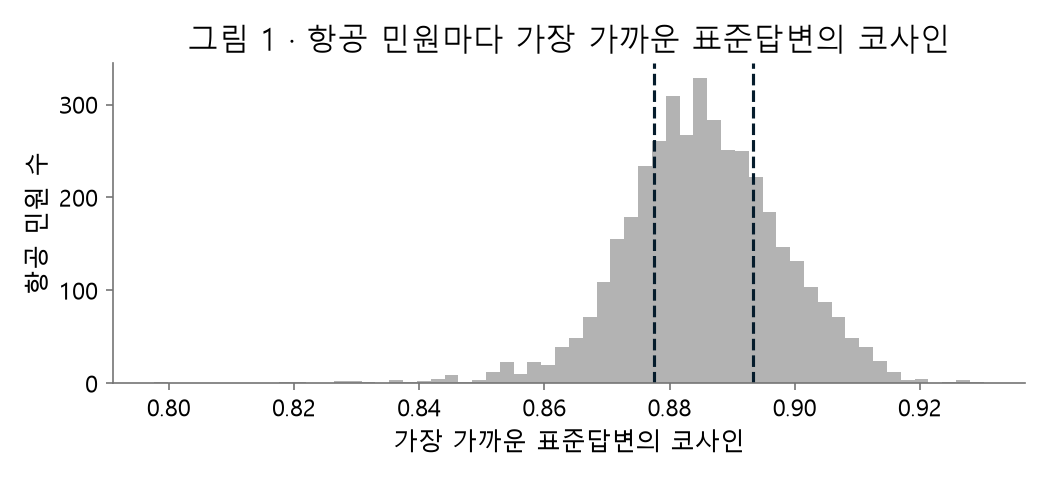

In [5]:
# 오늘의 준비 — 읽고 실행만 합니다
# [heavy] 항공 민원 제목과 표준답변 1,332개를 문장 인코더로 바꿔 표 1～3 과 그림 1 을 만듭니다. CPU 30초 · GPU 1분 안팎이고, 처음 한 번은 원자료와 가중치를 받느라 더 걸립니다
import os, re, time, hashlib, urllib.request
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from sentence_transformers import SentenceTransformer

# 실행 환경과 문장 인코더 — GPU 면 KURE-v1 · 항공 민원 전체, CPU 면 e5-small · 항공 민원 4,000건(시드 0)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if DEVICE == "cuda":
    MODEL_NAME, MODEL_REV, PREFIX, N_AIR = "nlpai-lab/KURE-v1", "8b418a58414668e75532ed045c22d9ca018ae2b2", "", None
else:
    MODEL_NAME, MODEL_REV, PREFIX, N_AIR = ("intfloat/multilingual-e5-small", "614241f622f53c4eeff9890bdc4f31cfecc418b3",
                                            "query: ", 4000)

# 원자료 — 원 출처 URL · 파일 이름 · SHA-256(2026-09-24 확인) · 데이터 페이지
RAW_FILES = {
    "complaints": ("https://www.data.go.kr/cmm/cmm/fileDownload.do?"
                   "atchFileId=FILE_000000002610054&fileDetailSn=1&insertDataPrcus=N",
                   "kftc_complaints_1.csv",
                   "50c098fea2ec1d05191d07c45cd0f75b4d0ac3b5e5ac36910fe40f2aab699ebe",
                   "https://www.data.go.kr/data/15098314/fileData.do"),
    "answers": ("https://www.data.go.kr/cmm/cmm/fileDownload.do?"
                "atchFileId=FILE_000000003197092&fileDetailSn=1&insertDataPrcus=N",
                "kca_std_answers.csv",
                "be5ad6ab3e2d6becbf6a32fe8f432c7bb2f575af10c017a42ce5e89bbffdf9d8",
                "https://www.data.go.kr/data/15144809/fileData.do"),
}
MIRROR_URL = "https://github.com/studio-js/korean-cx-text/raw/main/raw"   # 과정 복제본 — 원 출처와 같은 바이트, 먼저 받는 곳


def data_dir():
    # 자료 폴더: 환경변수 NLP_DATA_DIR 이 있으면 그 폴더, 없으면 ./nlp_data
    return os.environ.get("NLP_DATA_DIR", "nlp_data")


def find_local(name):
    # 자료 폴더 → cache/ → raw/ 순서로 찾아 처음 나온 경로, 없으면 None
    for sub in ("", "cache", "raw"):
        path = os.path.join(data_dir(), sub, name)
        if os.path.isfile(path):
            return path
    return None


def sha256_of(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(chunk), b""):
            h.update(block)
    return h.hexdigest()


def fetch_one(url, name):
    # url 에서 받아 자료 폴더/cache/ 에 두고 경로를 반환함 — 실패하면 세 번까지 다시 시도하고, 끝내 못 받으면 None
    path = os.path.join(data_dir(), "cache", name)
    os.makedirs(os.path.dirname(path), exist_ok=True)
    for i in range(3):
        try:
            urllib.request.urlretrieve(url, path + ".part")
            os.replace(path + ".part", path)
            return path
        except Exception as e:
            print(f"받기 실패 {i + 1}/3: {e}")
            time.sleep(2 * (i + 1))
    return None


def fetch_raw(name):
    # 원자료 경로: 로컬을 먼저 보고, 없으면 과정 복제본(MIRROR_URL) → 원 출처 URL 순서로 받음
    url, fname, sha, page = RAW_FILES[name]
    path = find_local(fname)
    if path is None:
        path = fetch_one(f"{MIRROR_URL}/{fname}", fname)
        if path is not None and sha256_of(path) != sha:   # 복제본이 다르면 버리고 원 출처로
            os.remove(path)
            path = None
    if path is None:
        path = fetch_one(url, fname)
    if path is None:
        raise RuntimeError(f"원 출처에서 파일을 받지 못했습니다. 데이터 페이지: {page}")
    if sha256_of(path) != sha:
        print(f"원 출처 파일이 바뀌었습니다. 결과 수가 교안과 다를 수 있습니다(데이터 페이지: {page})")
    return path


TEST_INPUT_RE = re.compile(   # 민원 파일의 시험 입력 행
    r"(?i)^\s*(?:test|테스트)\s*(?:입니다)?\s*\.?\s*$"
    r"|IN-TEST"
    r"|(?:인바운드|아웃바운드|녹취|수화기).*테스트|테스트.*(?:인바운드|아웃바운드|녹취|수화기)"
    r"|^\s*자동차\s*(?:상담\s*)?테스트"
    r"|^\s*\d{8}\s*[-_ ].*테스트"
    r"|테스트\s*데이터|상담\s*(?:전화\s*)?테스트|전화\s*테스트|헬프데스크\s*시험|^\s*일반\s*테스트")
EMPTY_TITLE_RE = re.compile(r"^[^가-힣A-Za-z]*$")   # 한글 음절도 로마자도 없는 제목
PHONE_RE = re.compile(r"(?<!\d)(?:01[016789]|0\d{1,2})[-.)\s]{0,2}\d{3,4}[-.\s]\d{4}(?!\d)")   # 전화번호 형태

# 후보 쌍 40개 — (민원 row_id, 표준답변 번호). 과정이 KURE-v1 코사인의 구간 5개에서 8쌍씩 뽑은 짝입니다
PAIR_IDS = [(367149, 1230), (46374, 1234), (12109, 1230), (183649, 1298), (122676, 1232), (111373, 1224),
            (28723, 719), (239236, 1234), (222824, 1054), (275200, 576), (440108, 1228), (302897, 1230),
            (367779, 1226), (125915, 1229), (213952, 1226), (331999, 1237), (93797, 1234), (240528, 1230),
            (134301, 1229), (20019, 1233), (400710, 887), (54381, 1230), (58079, 1231), (409279, 1234),
            (304266, 1234), (268718, 1153), (120628, 1234), (288451, 1230), (214295, 1230), (162502, 1230),
            (352979, 1231), (187463, 1230), (379974, 1225), (65639, 1224), (322661, 1234), (401674, 1298),
            (304447, 1234), (313528, 1230), (152334, 1234), (230532, 1224)]

# 항공 민원 — 시험 입력 · 빈 제목 행을 빼고 전화번호 형태를 [전화번호] 로 바꾼 뒤 품목명이 항공여객운송서비스인 행
t0 = time.time()
raw = pd.read_csv(fetch_raw("complaints"), encoding="cp949", dtype=str)
raw = raw.rename(columns=lambda c: c.split("(")[0].strip())
raw.insert(0, "row_id", range(len(raw)))
title = raw["사건제목"].fillna("").str.strip()
is_test = title.str.contains(TEST_INPUT_RE)
keep = ~is_test & ~(title.str.match(EMPTY_TITLE_RE) & ~is_test)
raw["사건제목"] = title.map(lambda t: PHONE_RE.sub("[전화번호]", t))
air_all = raw.loc[keep & (raw["품목명"] == "항공여객운송서비스"), ["row_id", "사건제목"]].reset_index(drop=True)
del raw, title
air = (air_all if N_AIR is None else air_all.sample(n=N_AIR, random_state=0)).reset_index(drop=True)

ans = pd.read_csv(fetch_raw("answers"), encoding="cp949", dtype={"번호": int})
for col in ["품목명", "구분", "질문"]:
    ans[col] = ans[col].astype(str).str.strip()

# 민원 제목과 표준답변 「질문」 열을 같은 문장 인코더로 바꿔, 민원마다 가장 가까운 답의 코사인을 구한다
model = SentenceTransformer(MODEL_NAME, device=DEVICE, revision=MODEL_REV)
model.max_seq_length = 256


def encode(texts):
    return model.encode([PREFIX + t for t in texts], batch_size=64, normalize_embeddings=True,
                        convert_to_numpy=True, show_progress_bar=False).astype(np.float32)


best = (encode(air["사건제목"]) @ encode(ans["질문"]).T).max(axis=1)   # 길이 1 벡터끼리의 내적 = 코사인
q25, q50, q75 = (float(v) for v in np.percentile(best, [25, 50, 75]))
thresholds = [q50 - 0.02, q50, q50 + 0.02]
unmatched = [100 * float((best < t).mean()) for t in thresholds]   # 가장 가까운 답의 코사인이 임계값보다 작은 민원의 비율
print(f"문장 인코더 {MODEL_NAME.split('/')[-1]} · 항공 민원 {len(air):,}건 · 표준답변 {len(ans):,}개 · {time.time() - t0:.0f}초")
print()

print("표 1 · 항공 민원마다 가장 가까운 표준답변의 코사인 (백분위수)")
print(f"  25백분위수 {q25:.3f} · 중앙값 {q50:.3f} · 75백분위수 {q75:.3f}")
print(f"  가장 작은 값 {best.min():.3f} · 가장 큰 값 {best.max():.3f}")
print()

print("표 2 · 임계값을 중앙값에서 0.02 씩 옮길 때 대응 없는 항공 민원 (%)")
for name, t, p in zip(["중앙값 − 0.02", "중앙값", "중앙값 + 0.02"], thresholds, unmatched):
    print(f"  {name:<9}  임계값 {t:.3f}  →  {p:4.1f} %")
print()

# 후보 쌍 40개에서 가장 가까운 답으로 많이 나온 표준답변 둘 — 쌍 수가 큰 순서, 같으면 번호 순서
pairs = pd.DataFrame(PAIR_IDS, columns=["row_id", "번호"])
pair_no = pairs["번호"].value_counts().rename_axis("번호").reset_index(name="쌍")
pair_no = pair_no.sort_values(["쌍", "번호"], ascending=[False, True]).head(2).merge(ans, on="번호")
by_row = air_all.set_index("row_id")["사건제목"]
print("표 3 · 후보 쌍 40개에서 가장 가까운 답으로 많이 나온 표준답변 (쌍)")
for no, cnt, kind, q in pair_no[["번호", "쌍", "구분", "질문"]].itertuples(index=False):
    eg = by_row[pairs.loc[pairs["번호"] == no, "row_id"].iloc[0]]   # 이 답을 가장 가까운 답으로 받은 첫 민원
    print(f"  {no} · {kind} · {cnt}쌍")
    print(f"     질문 「{q[:40]}…」")
    print(f"     이 답을 받은 민원 「{eg}」")

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(best, bins=60, color="#B3B3B3")
for v in (q25, q75):                       # 가운데 절반(25～75백분위수)의 두 경계
    ax.axvline(v, color="#051C2C", linestyle="--")
ax.set_xlabel("가장 가까운 표준답변의 코사인")
ax.set_ylabel("항공 민원 수")
ax.set_title("그림 1 · 항공 민원마다 가장 가까운 표준답변의 코사인")
plt.show()

가까운 글이 없을 때 상위 5 와 임계값
예를 들어 질의 하나와 리뷰 1,000건의 코사인을 구했더니 가장 큰 값이 0.93 이었다고 합시다. 상위 5 와 임계값 0.95 로 각각 고르면 몇 건일까요?

B 상위 5 는 5건, 임계값 0.95 는 0건이다

상위 k 는 코사인이 얼마든 늘 k 건을 고릅니다. 임계값은 기준을 넘는 글이 없으면 0건입니다. 상위 5 는 코사인이 큰 순서로 5건을 고르므로 0.93 이하인 글로 5건을 채웁니다. 임계값 0.95 이상인 글은 가장 큰 값이 0.93 이라 한 건도 없습니다.

둘 다 0건: 상위 k 에는 코사인의 아래 기준이 없습니다. 가까운 글이 없어도 k 건을 채웁니다.
둘 다 5건: 임계값은 건수를 정하지 않습니다. 기준 이상인 글만 고릅니다.
그래서 미션 1 의 이웃 20건도 늘 20건입니다. 질의와 같은 이야기인지는 원문을 읽어 확인합니다.

핵심 키워드: 상위 k 는 늘 k 건, 임계값은 0건일 수 있다, 원문을 읽어 확인

행렬곱 한 번이 코사인이 되는 조건
민원 제목 4,000건의 문장 임베딩을 한 행씩 모은 행렬이 AIR_EMB 이고, 질의 벡터가 q 입니다. AIR_EMB @ q 는 수 4,000개입니다. 이 수가 질의와 제목마다의 코사인이 되려면 벡터에 무엇이 필요할까요? 이유를 한두 문장으로 적어 보세요.

max(axis=1)을 설정해서 1에 가까운지 확인해야합니다.

두 벡터 모두 길이가 1 이어야 합니다. 코사인은 내적을 두 길이의 곱으로 나눈 값입니다. 두 길이가 1 이면 분모가 1 이라 내적이 곧 코사인입니다.

AIR_EMB @ q 의 i 번째 수는 AIR_EMB 의 i 번째 행과 q 의 내적입니다. 인코딩할 때 normalize_embeddings=True 를 주면 벡터마다 길이를 1 로 맞춥니다. 그래서 행렬곱 한 번으로 코사인 4,000개를 한꺼번에 구합니다.

길이를 맞추지 않으면 이 수는 코사인이 아니라 길이까지 곱한 내적입니다. 미션 1 에서 출력하는 문장 임베딩 길이가 이 조건을 확인하는 값입니다.

모범 답: 「두 벡터의 길이가 모두 1 이어야 한다. 코사인은 내적 ÷ 두 길이의 곱이라 두 길이가 1 이면 내적이 곧 코사인이다.」

채점할 때 볼 것

① 질의 벡터와 제목 벡터 모두 길이가 1 이어야 한다고 적었는가

② 코사인 = 내적 ÷ 두 길이의 곱이라 분모가 1 이 된다고 설명했는가

③ 행렬곱의 수 하나가 행 하나와 질의 벡터의 내적이라는 것을 적었는가

핵심 키워드: 코사인 = 내적 ÷ 두 길이의 곱, 길이 1 로 정규화, 행렬곱 한 번 = 모든 코사인

가장 가까운 답의 코사인이 모인 범위
「오늘의 준비」 셀을 실행하면 나오는 「표 1 · 항공 민원마다 가장 가까운 표준답변의 코사인 (백분위수)」와 「그림 1 · 항공 민원마다 가장 가까운 표준답변의 코사인」을 봅니다. 가운데 절반(25～75백분위수)이 모인 구간의 길이는 얼마쯤일까요?

A 0.1 보다 좁다


이 구간의 길이는 75백분위수에서 25백분위수를 뺀 값입니다. GPU 의 KURE-v1 에서는 0.685 − 0.628 = 0.057 입니다. CPU 의 e5-small 에서는 약 0.016 입니다. 코사인은 −1 에서 1 까지인데, 민원의 절반이 길이 0.1 도 안 되는 구간에 모였습니다.

0.1 에서 0.3 사이 · 0.3 보다 넓다: 그림 1 의 양 끝까지 읽은 답입니다. 가장 작은 값과 가장 큰 값 사이에는 민원이 드문드문 있습니다. 가운데 절반은 두 파선 사이의 좁은 구간입니다.
그래서 임계값을 조금만 옮겨도 대응 없는 민원의 건수가 크게 달라집니다. 표 2 가 그 크기입니다.

핵심 키워드: 25～75백분위수 구간의 길이, 좁은 구간에 모인 코사인, 작은 차이로 크게 바뀌는 건수

중앙값을 임계값으로 쓴 대응 없는 민원
「오늘의 준비」 셀을 실행하면 나오는 「표 2 · 임계값을 중앙값에서 0.02 씩 옮길 때 대응 없는 항공 민원 (%)」를 봅니다. 이 표로 「항공 민원의 절반은 대응하는 표준답변이 없다」고 말할 수 있을까요?

B 말할 수 없다: 쌍을 읽어 정한 임계값이 아니고, 0.02 에 크게 바뀐다

이 50.0 % 는 임계값을 중앙값으로 골라서 생긴 값입니다. 중앙값은 민원의 절반이 그 아래인 코사인이라 어느 모델에서든 50.0 % 가 나옵니다. 임계값을 0.02 만 옮겨도 GPU 의 KURE-v1 은 약 33～69 %, CPU 의 e5-small 은 약 5～94 % 입니다.

50.0 % 로 나왔다: 비율이 임계값을 고른 방법에서 나왔습니다. 민원과 답을 읽어 확인한 값이 아닙니다.
세 비율의 평균: 근거 없는 임계값 3개의 결과를 평균해도 근거가 생기지 않습니다.
그래서 임계값은 쓰는 모델에서 코사인 구간마다 쌍을 무작위로 뽑아 읽고 정밀도로 정합니다. 비율 옆에는 모델 이름과 임계값의 근거를 함께 적습니다.

핵심 키워드: 중앙값 임계값이면 50 %, 임계값에 따라 바뀌는 비율, 쌍을 읽어 정한 임계값

후보 쌍 40개에 가장 많이 나온 답
「오늘의 준비」 셀을 실행하면 나오는 「표 3 · 후보 쌍 40개에서 가장 가까운 답으로 많이 나온 표준답변 (쌍)」을 봅니다. 번호 1230 을 가장 가까운 답으로 받은 민원을 「대응하는 답이 있음」으로 집계해도 될까요?

C 집계하지 않는다: 질문이 미성년자 결제라 민원과 다른 이야기다

가장 가까운 답이 맞는 답이라는 보장은 없습니다. 표 3 에서 1230 은 「청약철회_미성년자 계약」이고 40쌍 가운데 10쌍의 가장 가까운 답입니다. 질문은 미성년 자녀가 부모 동의 없이 산 항공권 이야기입니다. 이 답을 받은 민원은 결항 뒤의 취소수수료가 부당하다는 이야기입니다.

같은 항공 품목: 품목이 같아도 누가 무엇을 해서 무엇이 문제인지가 다릅니다.
가장 많이 나온 답: 많이 나온 것은 코사인이 높았다는 뜻입니다. 맞는 답인지는 읽어 봐야 압니다.
그래서 대응하는 답이 있는지는 민원과 답의 원문을 읽어 확인합니다. 1234 「일방적인 항공편 취소」처럼 같은 사정을 다루는 답도 있어, 쌍마다 읽어야 합니다.

핵심 키워드: 가장 가까운 답 ≠ 맞는 답, 같은 품목이어도 다른 사정, 원문을 읽어 확인

In [6]:
# 미션 1 · 준비 — 읽고 실행만 합니다. 이 셀이 미션 1 에 쓸 이름을 직접 만듭니다
#  민원 원자료를 과정 복제본에서 한 번 받아 두고(67.9MB), 항공 민원 제목을 형태소 명사로 나눕니다. 10초 안팎 걸립니다
#  문장 인코더는 불러 두지 않습니다 — 인코딩은 PROMPT 셀에서 DEVICE · MODEL_NAME · MODEL_REV · PREFIX 로 합니다
import os, re, time, math, hashlib, urllib.request
from decimal import Decimal, ROUND_HALF_UP
import numpy as np
import pandas as pd
import torch
from kiwipiepy import Kiwi
import matplotlib.pyplot as plt

COL = {"남색": "#051C2C", "파랑": "#2251FF", "하늘색": "#00A9F4",   # 맨 위 셀과 같은 색 · 캔버스 폭 —
       "회색": "#757575", "연회색": "#B3B3B3"}                        #  이 셀만 실행해도 정해집니다
FIG_W = 10.0

# 실행 환경과 문장 인코더 설정 — 맨 위 환경 확인 셀과 같은 방법(이 셀만 실행해도 정해집니다)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if DEVICE == "cuda":
    MODEL_NAME, MODEL_REV, PREFIX = "nlpai-lab/KURE-v1", "8b418a58414668e75532ed045c22d9ca018ae2b2", ""
    N_AIR = None                     # 항공 민원 전체
else:
    MODEL_NAME, MODEL_REV, PREFIX = "intfloat/multilingual-e5-small", "614241f622f53c4eeff9890bdc4f31cfecc418b3", "query: "
    N_AIR = 4000                     # 항공 민원 가운데 4,000건(시드 0)

# 원자료 — 원 출처 URL · 파일 이름 · SHA-256(2026-09-24 확인) · 데이터 페이지
RAW_FILES = {
    "complaints": ("https://www.data.go.kr/cmm/cmm/fileDownload.do?"
                   "atchFileId=FILE_000000002610054&fileDetailSn=1&insertDataPrcus=N",
                   "kftc_complaints_1.csv",
                   "50c098fea2ec1d05191d07c45cd0f75b4d0ac3b5e5ac36910fe40f2aab699ebe",
                   "https://www.data.go.kr/data/15098314/fileData.do"),
}
MIRROR_URL = "https://github.com/studio-js/korean-cx-text/raw/main/raw"   # 과정 복제본 — 원 출처와 같은 바이트, 먼저 받는 곳


def data_dir():
    # 자료 폴더: 환경변수 NLP_DATA_DIR 이 있으면 그 폴더, 없으면 ./nlp_data
    return os.environ.get("NLP_DATA_DIR", "nlp_data")


def find_local(name):
    # 자료 폴더 → cache/ → raw/ 순서로 찾아 처음 나온 경로, 없으면 None
    for sub in ("", "cache", "raw"):
        path = os.path.join(data_dir(), sub, name)
        if os.path.isfile(path):
            return path
    return None


def sha256_of(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(chunk), b""):
            h.update(block)
    return h.hexdigest()


def _download(url, path, retries=3):
    # url 을 path.part 로 받아 두고 성공하면 True — 실패하면 세 번까지 다시 시도
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    for i in range(retries):
        try:
            urllib.request.urlretrieve(url, path + ".part")
            return True
        except Exception as e:
            print(f"받기 실패 {i + 1}/{retries}: {e}")
            time.sleep(2 * (i + 1))
    return False


def _fetch(url, name, sha=None, strict=False):
    # 로컬에 있으면 그 경로, 없으면 url 에서 받아 SHA-256 확인 뒤 자료 폴더/cache/ 에 두고 경로를 반환함(받지 못하면 None)
    path = find_local(name)
    if path is None:
        path = os.path.join(data_dir(), "cache", name)
        if not _download(url, path):
            return None
        if strict and sha and sha256_of(path + ".part") != sha:
            os.remove(path + ".part")
            raise RuntimeError(f"받은 {name} 의 SHA-256 이 맞지 않습니다. 다시 실행해 보세요.")
        os.replace(path + ".part", path)
    return path


def fetch_raw(name):
    # 원자료 경로: 로컬을 먼저 보고, 없으면 과정 복제본(MIRROR_URL) → 원 출처 URL 순서로 받음
    url, fname, sha, page = RAW_FILES[name]
    path = find_local(fname)
    if path is None:
        path = _fetch(f"{MIRROR_URL}/{fname}", fname)
        if path is not None and sha256_of(path) != sha:  # 복제본이 다르면 버리고 원 출처로
            os.remove(path)
            path = None
    if path is None:
        path = _fetch(url, fname)
    if path is None:
        raise RuntimeError(f"원 출처에서 파일을 받지 못했습니다. 데이터 페이지: {page}")
    if sha256_of(path) != sha:
        print(f"원 출처 파일이 바뀌었습니다. 결과 수가 교안과 다를 수 있습니다(데이터 페이지: {page})")
    return path


def rnd(x, digits):
    # 십진 값 기준 반올림(끝자리 5 는 올림) — 교안의 수와 같은 방식
    return float(Decimal(f"{float(x):.12g}").quantize(Decimal(1).scaleb(-digits), rounding=ROUND_HALF_UP))


# 민원 파일 읽기 — 이 과목에서 해 온 전처리 그대로: 시험 입력·빈 제목 행을 빼고, 전화번호 형태를 [전화번호] 로 바꾼다
TEST_INPUT_RE = re.compile(
    r"(?i)^\s*(?:test|테스트)\s*(?:입니다)?\s*\.?\s*$"
    r"|IN-TEST"
    r"|(?:인바운드|아웃바운드|녹취|수화기).*테스트|테스트.*(?:인바운드|아웃바운드|녹취|수화기)"
    r"|^\s*자동차\s*(?:상담\s*)?테스트"
    r"|^\s*\d{8}\s*[-_ ].*테스트"
    r"|테스트\s*데이터|상담\s*(?:전화\s*)?테스트|전화\s*테스트|헬프데스크\s*시험|^\s*일반\s*테스트")
EMPTY_TITLE_RE = re.compile(r"^[^가-힣A-Za-z]*$")   # 한글 음절도 로마자도 없는 제목(「-」「.」「0」「ㅇ」)
PHONE_RE = re.compile(r"(?<!\d)(?:01[016789]|0\d{1,2})[-.)\s]{0,2}\d{3,4}[-.\s]\d{4}(?!\d)")


def read_complaints(path, verbose=True):
    # 민원 파일(cp949) 읽기 → 열 이름에서 괄호 안 영문을 떼고, 시험 입력·빈 제목 행을 빼고, 전화번호 형태를 [전화번호] 로 바꾼다
    raw = pd.read_csv(path, encoding="cp949", dtype=str)
    df = raw.rename(columns=lambda c: c.split("(")[0].strip())
    df.insert(0, "row_id", range(len(df)))          # 원자료의 행 번호(0부터)
    title = df["사건제목"].fillna("").str.strip()
    is_test = title.str.contains(TEST_INPUT_RE)
    is_empty = title.str.match(EMPTY_TITLE_RE) & ~is_test
    df = df[~is_test & ~is_empty].copy()
    title = title[df.index]
    df["사건제목"] = title.map(lambda t: PHONE_RE.sub("[전화번호]", t))
    n_masked = int(df["사건제목"].ne(title).sum())
    df["접수일자"] = pd.to_datetime(df["접수일자"], format="%Y-%m-%d")
    df = df.reset_index(drop=True)
    if verbose:
        print(f"민원 원본 {len(raw):,}행 → 시험 입력 {int(is_test.sum())}행·빈 제목 {int(is_empty.sum())}행 제거"
              f" → {len(df):,}행, 전화번호 형태 가림 {n_masked}행")
    return df


def sample_rows(df, n, seed=0):
    # 고정 표본: 같은 입력과 같은 seed 면 같은 행이 같은 순서로 나온다
    return df.sample(n=n, random_state=seed)


def kiwi_nouns(texts, kiwi):
    # 문서마다 명사(NNG·NNP) 목록 — 순서와 반복을 그대로 둔다
    return [[t.form for t in toks if t.tag in ("NNG", "NNP")] for toks in kiwi.tokenize(list(texts))]


AIRLINE = "항공여객운송서비스"          # 민원 품목명 — 항공여객운송서비스

COMPLAINTS_PATH = fetch_raw("complaints")
_c = read_complaints(COMPLAINTS_PATH)
AIR_ALL = _c.loc[_c["품목명"] == AIRLINE, ["row_id", "접수일자", "사건제목"]].reset_index(drop=True)
del _c                                               # 민원 전체 표는 더 쓰지 않는다
AIR = (AIR_ALL if N_AIR is None else sample_rows(AIR_ALL, N_AIR, seed=0)).reset_index(drop=True)   # 쓸 변수 — 항공 민원
import os
os.environ.setdefault("KIWI_ARCH_TYPE", "balanced")  # CPU 종류(Mac·Colab)와 상관없이 형태소 분석 결과를 같게
KIWI = Kiwi(num_workers=2)
AIR["명사"] = kiwi_nouns(AIR["사건제목"], KIWI)          # 제목마다 형태소 명사 목록

QUERY = "코로나로 항공권 환불을 거부당함"             # 쓸 변수 — 질의 문장
KEYWORD, TOP_K = "환불", 20                          # 쓸 변수 — 키워드(형태소 명사) · 이웃 수

print(f"항공 민원 {len(AIR_ALL):,}건 가운데 {len(AIR):,}건 준비"
      + (" (전체)" if N_AIR is None else " (시드 0)")
      + f" · 명사 「{KEYWORD}」 가 있는 제목 {int(AIR['명사'].map(lambda ns: KEYWORD in ns).sum()):,}건")
print(f"DEVICE : {DEVICE} · 문장 인코더 : {MODEL_NAME} · 접두어 PREFIX = {PREFIX!r}")
print("쓸 수 있는 이름 : AIR · QUERY · KEYWORD · TOP_K · DEVICE · MODEL_NAME · MODEL_REV · PREFIX · rnd · KIWI · COL · FIG_W")

민원 원본 499,999행 → 시험 입력 91행·빈 제목 64행 제거 → 499,844행, 전화번호 형태 가림 10행
항공 민원 12,232건 가운데 4,000건 준비 (시드 0) · 명사 「환불」 가 있는 제목 1,866건
DEVICE : cpu · 문장 인코더 : intfloat/multilingual-e5-small · 접두어 PREFIX = 'query: '
쓸 수 있는 이름 : AIR · QUERY · KEYWORD · TOP_K · DEVICE · MODEL_NAME · MODEL_REV · PREFIX · rnd · KIWI · COL · FIG_W


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 2305.58it/s]


이웃 20건 중 「환불」 없는 민원 = 2 건
문장 임베딩 길이 = 1.0000


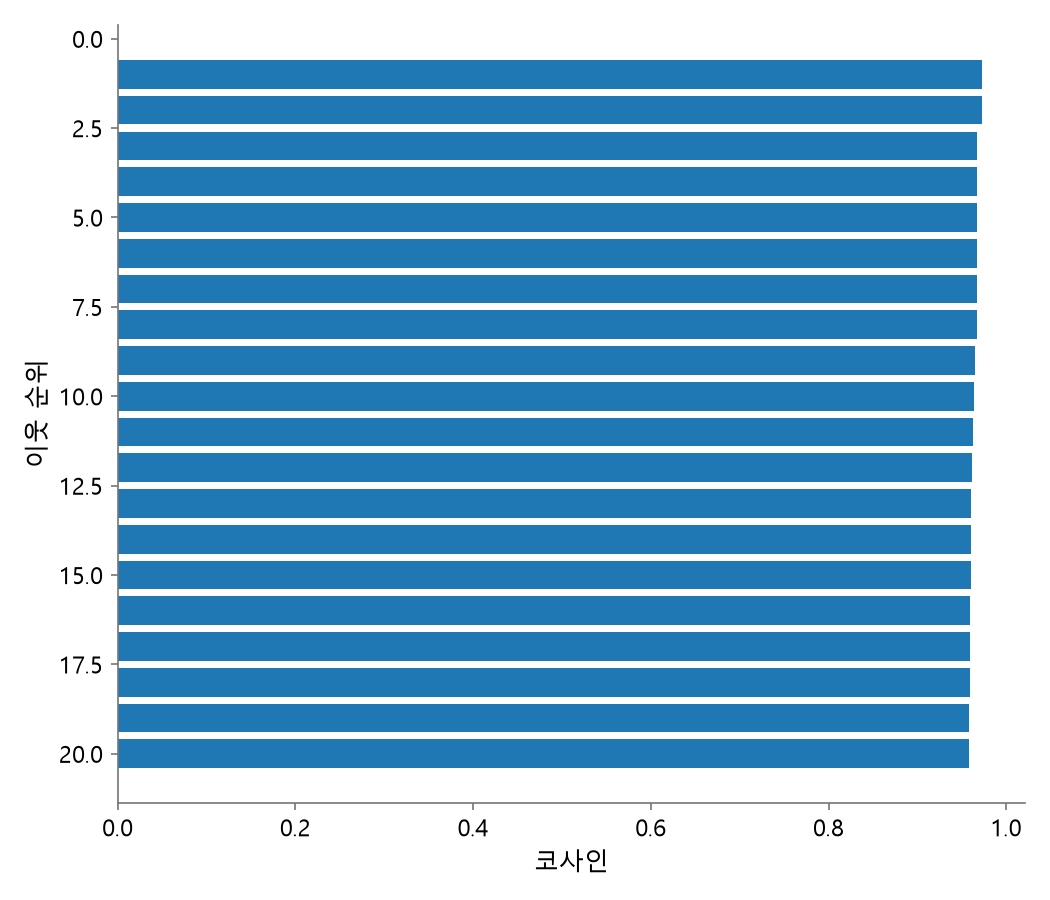

In [7]:
# 미션 1 — 프롬프트   # ai: prompt
# PROMPT 를 쓰고 → AI 튜터에 "위 PROMPT 대로 코드를 써 줘" → 「이 셀에 넣기」 → ▶
# 시킬 일은 AI 튜터 대화창이 아니라 아래 PROMPT 따옴표 안에 적습니다. 따옴표 안이 비어 있으면 채점과 완성본 풀이가 잠깁니다
PROMPT = """
이 미션의 질문: 질의 「코로나로 항공권 환불을 거부당함」과 가장 가까운 항공 민원 20건 가운데 「환불」이 없는 민원은 몇 건일까요?
미션 1 준비 셀에서 만든 변수와 함수들은 수정 및 별도 추가하지 않고 그대로 사용해
AIR · QUERY · KEYWORD · TOP_K · DEVICE · MODEL_NAME · MODEL_REV · PREFIX

1. 이웃 20건 중 [환불] 없는 민원: 건, 정수 / 질의와 코사인이 큰 20건 가운데 명사 목록에 KEYWORD가 없는 민원 수
2. 문장 임베디 길이: 소수점 아래 넷째까지
3. 그래프
가로축: 코사인
세로축: 이웃 순위
이웃 20건의 가로 막대 20개

"""
# --- 여기부터 AI 코드 ---
import numpy as np
import matplotlib.pyplot as plt
from sentence_transformers import SentenceTransformer

# 가정: AIR 의 제목 열은 "제목", 명사 목록 열은 "명사". 다르면 KeyError 가 나므로 AIR.columns 로 확인해 여기만 바꾸세요.
TITLE_COL, NOUN_COL = "사건제목", "명사"

model = SentenceTransformer(MODEL_NAME, revision=MODEL_REV, device=DEVICE)
AIR_EMB = model.encode([PREFIX + t for t in AIR[TITLE_COL]], normalize_embeddings=True)
q = model.encode(PREFIX + QUERY, normalize_embeddings=True)

cos = AIR_EMB @ q
top = np.argsort(-cos)[:TOP_K]  # 코사인이 큰 순서

# 제목 문자열이 아니라 명사 열에서 KEYWORD 확인
no_kw = sum(KEYWORD not in AIR[NOUN_COL].iloc[i] for i in top)

print(f"이웃 20건 중 「환불」 없는 민원 = {no_kw} 건")
print(f"문장 임베딩 길이 = {np.linalg.norm(AIR_EMB[0]):.4f}")

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False
fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(np.arange(1, TOP_K + 1), cos[top])
ax.invert_yaxis()  # 1위가 위로
ax.set_xlabel("코사인")
ax.set_ylabel("이웃 순위")
plt.tight_layout()
plt.show()

In [8]:
# 미션 2 · 준비 — 읽고 실행만 합니다. 이 셀이 미션 2 에 쓸 이름을 직접 만듭니다
#  리뷰 원자료를 과정 복제본에서 한 번 받아 두고(20.6MB), 고정 표본의 앞 N_REV 건을 고릅니다. 몇 초면 끝납니다
#  문장 인코더는 불러 두지 않습니다 — embed 를 처음 호출할 때 그 모델을 DEVICE 로 옮깁니다
import os, re, time, math, hashlib, urllib.request
from decimal import Decimal, ROUND_HALF_UP
import numpy as np
import pandas as pd
import torch
from sentence_transformers import SentenceTransformer
import matplotlib.pyplot as plt

COL = {"남색": "#051C2C", "파랑": "#2251FF", "하늘색": "#00A9F4",   # 맨 위 셀과 같은 색 · 캔버스 폭 —
       "회색": "#757575", "연회색": "#B3B3B3"}                        #  이 셀만 실행해도 정해집니다
FIG_W = 10.0

# 실행 환경 — 맨 위 환경 확인 셀과 같은 방법(이 셀만 실행해도 정해집니다)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
N_REV = 3000 if DEVICE == "cuda" else 1000          # 리뷰 건수 — GPU 3,000건 · CPU 1,000건

# 문장 인코더 둘 — 허브 이름 · 버전(revision) · 문장 접두어
ENCODERS = {
    "KURE-v1": ("nlpai-lab/KURE-v1", "8b418a58414668e75532ed045c22d9ca018ae2b2", ""),
    "e5-small": ("intfloat/multilingual-e5-small", "614241f622f53c4eeff9890bdc4f31cfecc418b3", "query: "),
}
OLD_THRESHOLD = 0.90          # 전임 담당자가 KURE-v1 에서 코사인이 높은 쌍을 읽어 정한 임계값

# 원자료 — 원 출처 URL · 파일 이름 · SHA-256(2026-09-24 확인) · 데이터 페이지
RAW_FILES = {
    "reviews": ("https://raw.githubusercontent.com/bab2min/corpus/master/sentiment/naver_shopping.txt",
                "naver_shopping.txt",
                "dc4d1aca0a148671cbe80bcb81962eee297370acab42be93c1617ce9336479c0",
                "https://github.com/bab2min/corpus/tree/master/sentiment"),
}
MIRROR_URL = "https://github.com/studio-js/korean-cx-text/raw/main/raw"   # 과정 복제본 — 원 출처와 같은 바이트, 먼저 받는 곳


def data_dir():
    # 자료 폴더: 환경변수 NLP_DATA_DIR 이 있으면 그 폴더, 없으면 ./nlp_data
    return os.environ.get("NLP_DATA_DIR", "nlp_data")


def find_local(name):
    # 자료 폴더 → cache/ → raw/ 순서로 찾아 처음 나온 경로, 없으면 None
    for sub in ("", "cache", "raw"):
        path = os.path.join(data_dir(), sub, name)
        if os.path.isfile(path):
            return path
    return None


def sha256_of(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(chunk), b""):
            h.update(block)
    return h.hexdigest()


def _download(url, path, retries=3):
    # url 을 path.part 로 받아 두고 성공하면 True — 실패하면 세 번까지 다시 시도
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    for i in range(retries):
        try:
            urllib.request.urlretrieve(url, path + ".part")
            return True
        except Exception as e:
            print(f"받기 실패 {i + 1}/{retries}: {e}")
            time.sleep(2 * (i + 1))
    return False


def _fetch(url, name, sha=None, strict=False):
    # 로컬에 있으면 그 경로, 없으면 url 에서 받아 SHA-256 확인 뒤 자료 폴더/cache/ 에 두고 경로를 반환함(받지 못하면 None)
    path = find_local(name)
    if path is None:
        path = os.path.join(data_dir(), "cache", name)
        if not _download(url, path):
            return None
        if strict and sha and sha256_of(path + ".part") != sha:
            os.remove(path + ".part")
            raise RuntimeError(f"받은 {name} 의 SHA-256 이 맞지 않습니다. 다시 실행해 보세요.")
        os.replace(path + ".part", path)
    return path


def fetch_raw(name):
    # 원자료 경로: 로컬을 먼저 보고, 없으면 과정 복제본(MIRROR_URL) → 원 출처 URL 순서로 받음
    url, fname, sha, page = RAW_FILES[name]
    path = find_local(fname)
    if path is None:
        path = _fetch(f"{MIRROR_URL}/{fname}", fname)
        if path is not None and sha256_of(path) != sha:  # 복제본이 다르면 버리고 원 출처로
            os.remove(path)
            path = None
    if path is None:
        path = _fetch(url, fname)
    if path is None:
        raise RuntimeError(f"원 출처에서 파일을 받지 못했습니다. 데이터 페이지: {page}")
    if sha256_of(path) != sha:
        print(f"원 출처 파일이 바뀌었습니다. 결과 수가 교안과 다를 수 있습니다(데이터 페이지: {page})")
    return path


def rnd(x, digits):
    # 십진 값 기준 반올림(끝자리 5 는 올림) — 교안의 수와 같은 방식
    return float(Decimal(f"{float(x):.12g}").quantize(Decimal(1).scaleb(-digits), rounding=ROUND_HALF_UP))


# 리뷰 파일 읽기 — 이 과목에서 써 온 잡음 정리 그대로: 반복 자모는 두 글자로 줄이고, 자음 넷 이상의 자모 나열은 지운다
JAMO_RUN_RE = re.compile(r"[ㄱ-ㅣㆍ]{4,}")                 # 낱자모가 네 글자 이상 이어진 자리


def _consonants(run):
    # 서로 다른 자음 개수
    return len(set(re.findall(r"[ㄱ-ㅎ]", run)))


def clean_review(text):
    # 반복 자모는 두 글자로 줄이고 자모 나열은 지우며 띄어쓰기는 쓴 대로 둔다
    text = JAMO_RUN_RE.sub(lambda m: "" if _consonants(m.group()) >= 4 else m.group(), text)
    text = re.sub(r"([ㄱ-ㅎㅏ-ㅣ])\1{2,}", r"\1\1", text)
    return re.sub(r"\s{2,}", " ", text).strip()


def read_reviews(path):
    # 리뷰 파일(탭 구분: 별점 · 본문) 읽기 → 파일의 행 번호 row_id 와 본문_정리 열
    rows = [line.split("\t", 1) for line in open(path, encoding="utf-8").read().split("\n") if line]
    df = pd.DataFrame(rows, columns=["별점", "본문"])
    df.insert(0, "row_id", range(len(df)))
    df["별점"] = df["별점"].astype(int)
    df["본문_정리"] = df["본문"].map(clean_review)
    return df


def sample_rows(df, n, seed=0):
    # 고정 표본: 같은 입력과 같은 seed 면 같은 행이 같은 순서로 나온다
    return df.sample(n=n, random_state=seed)


_ENCODER_CACHE = {}                                    # 한 번 부른 문장 인코더를 다시 받지 않게 둔다


def embed(name, texts):
    # ENCODERS[name] 의 문장 인코더로 문장마다 길이 1 벡터 한 행(float32) — DEVICE 에서 인코딩한다
    hub, rev, prefix = ENCODERS[name]
    if name not in _ENCODER_CACHE:
        _ENCODER_CACHE[name] = SentenceTransformer(hub, device=DEVICE, revision=rev)
        _ENCODER_CACHE[name].max_seq_length = 256
    vecs = _ENCODER_CACHE[name].encode([prefix + t for t in texts], batch_size=64, normalize_embeddings=True,
                                       convert_to_numpy=True, show_progress_bar=False)
    return vecs.astype(np.float32)


REVIEWS_PATH = fetch_raw("reviews")
_r = read_reviews(REVIEWS_PATH)
REV = sample_rows(_r, 20000, seed=0).head(N_REV)[["row_id", "별점", "본문_정리"]].reset_index(drop=True)   # 쓸 변수 — 리뷰
del _r                                               # 리뷰 20만 건 전체 표는 더 쓰지 않는다
LOW = (REV["별점"] <= 2).to_numpy()                  # 쓸 변수 — 별점 1 · 2점이면 True

print(f"리뷰 {len(REV):,}건 준비 (표본 2만 건의 앞 {N_REV:,}건, 시드 0) · 별점 1 · 2점 {int(LOW.sum()):,}건"
      f" · 모든 쌍 {len(REV) * (len(REV) - 1) // 2:,}쌍")
print(f"DEVICE : {DEVICE} · 문장 인코더 둘 : " + " · ".join(ENCODERS) + f" · 옛 임계값 OLD_THRESHOLD = {OLD_THRESHOLD}")
print("쓸 수 있는 이름 : REV · LOW · ENCODERS · embed · OLD_THRESHOLD · N_REV · DEVICE · rnd · COL · FIG_W")

리뷰 1,000건 준비 (표본 2만 건의 앞 1,000건, 시드 0) · 별점 1 · 2점 518건 · 모든 쌍 499,500쌍
DEVICE : cpu · 문장 인코더 둘 : KURE-v1 · e5-small · 옛 임계값 OLD_THRESHOLD = 0.9
쓸 수 있는 이름 : REV · LOW · ENCODERS · embed · OLD_THRESHOLD · N_REV · DEVICE · rnd · COL · FIG_W


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1810.76it/s]


모델 = e5-small · 임계값 = 0.90
임계값 이상인 쌍 = 19,654 쌍 · 별점 갈린 쌍 = 24.4 %
거의 같은 글이 있는 리뷰 = 892 건 (89.2 %)
판단 : 리뷰 대부분이 복사한 글이라 별점 평균을 믿을 수 없다


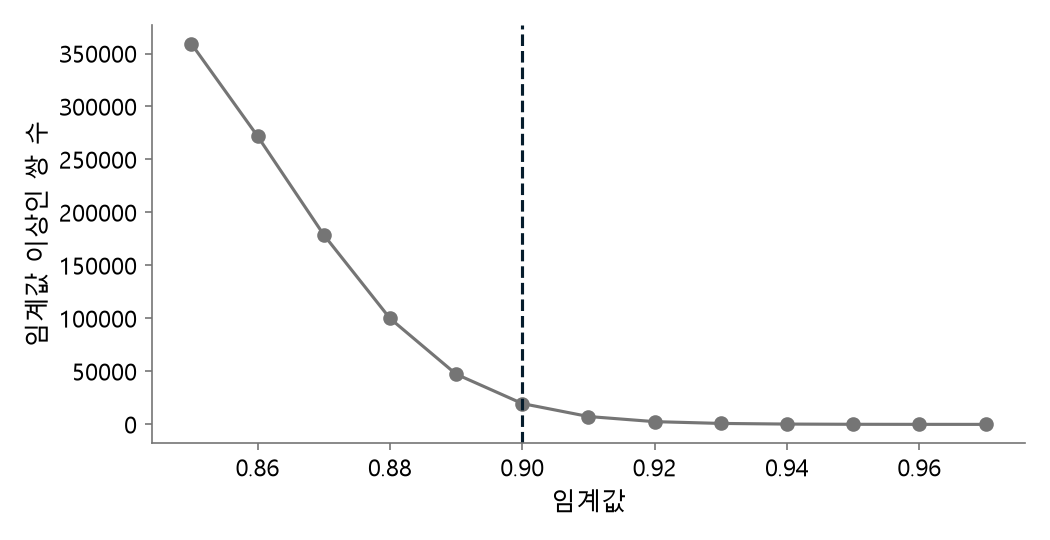

In [9]:
# 미션 2 — 프롬프트 (함정)   # ai: prompt
# [heavy] 고친 뒤에는 두 모델로 인코딩해 CPU 에서 1분 가까이 걸릴 수 있습니다
# 이 미션은 함정입니다 — 아래는 전임 담당자가 남긴 코드라 오류 없이 실행되지만 결론을 믿을 수 없습니다.
# 고칠 지시는 AI 튜터 대화창이 아니라 아래 PROMPT 따옴표 안에 적습니다. 따옴표 안이 비어 있으면 아래 코드의 진단만 나오고 완성본 풀이는 잠깁니다
# 지시를 적고 AI 튜터에 "위 PROMPT 대로 코드를 써 줘" → 「이 셀에 넣기」 → ▶ 하면 AI 튜터가 AI 코드 표시선 아래를 다시 씁니다
PROMPT = """

"""
# --- 여기부터 AI 코드 ---
# ↓ 전임 담당자의 코드 — 「리뷰 대부분이 복사한 글」이라고 판단한 근거인 중복 집계. 그대로 실행하면 채점이 ❌ 를 냅니다
E = embed("e5-small", REV["본문_정리"])                  # 인코더만 e5-small 로 바꿨다
S = E @ E.T                                             # 길이 1 벡터끼리의 내적 = 모든 쌍의 코사인
iu = np.triu_indices(len(REV), 1)                       # 위 삼각 — 같은 쌍을 두 번 집계하지 않게
cos = S[iu]
m = cos >= OLD_THRESHOLD
split = (LOW[iu[0]] != LOW[iu[1]])[m]                   # 별점 1 · 2점과 4 · 5점이 짝인 쌍
inpair = np.zeros(len(REV), bool)
inpair[iu[0][m]] = True
inpair[iu[1][m]] = True
print(f"모델 = e5-small · 임계값 = {OLD_THRESHOLD:.2f}")
print(f"임계값 이상인 쌍 = {int(m.sum()):,} 쌍 · 별점 갈린 쌍 = {rnd(100 * split.mean(), 1):.1f} %")
print(f"거의 같은 글이 있는 리뷰 = {int(inpair.sum()):,} 건 ({rnd(100 * inpair.mean(), 1):.1f} %)")
print("판단 : 리뷰 대부분이 복사한 글이라 별점 평균을 믿을 수 없다")

grid = np.round(np.arange(0.85, 0.9701, 0.01), 2)       # 임계값 0.85 ～ 0.97
fig, ax = plt.subplots(figsize=(FIG_W * 0.7, 3.6))
ax.plot(grid, [int((cos >= t).sum()) for t in grid], marker="o", color=COL["회색"])
ax.axvline(OLD_THRESHOLD, color=COL["남색"], linestyle="--")
ax.set_xlabel("임계값")
ax.set_ylabel("임계값 이상인 쌍 수")
plt.show()

Loading weights: 100%|██████████| 391/391 [00:01<00:00, 254.73it/s]


KURE-v1 임계값 0.90 쌍 = 13 쌍
e5-small 임계값 0.90 쌍 = 19,654 쌍
별점 갈린 비율 KURE-v1 = 0.0 %
별점 갈린 비율 e5-small = 24.4 %
e5-small 다시 정한 임계값 = 0.9646
다시 정한 임계값에서 e5-small 쌍 = 13 쌍
거의 같은 글이 있는 리뷰 = 14 건 (1.4 %)


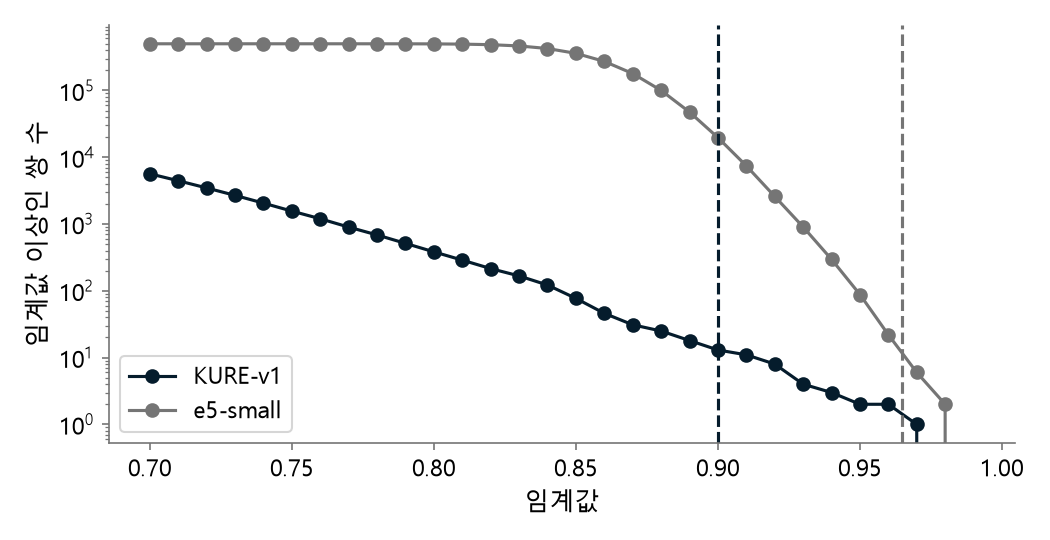

In [10]:
# 미션 2 — 프롬프트 (함정)   # ai: prompt
# [heavy] 고친 뒤에는 두 모델로 인코딩해 CPU 에서 1분 가까이 걸릴 수 있습니다
# 이 미션은 함정입니다 — 아래는 전임 담당자가 남긴 코드라 오류 없이 실행되지만 결론을 믿을 수 없습니다.
# 고칠 지시는 AI 튜터 대화창이 아니라 아래 PROMPT 따옴표 안에 적습니다. 따옴표 안이 비어 있으면 아래 코드의 진단만 나오고 완성본 풀이는 잠깁니다
# 지시를 적고 AI 튜터에 "위 PROMPT 대로 코드를 써 줘" → 「이 셀에 넣기」 → ▶ 하면 AI 튜터가 AI 코드 표시선 아래를 다시 씁니다
PROMPT = """
전임자 코드에서 S = E @ E.T를하고 Max = 1을 지정하지 않아서 잘못된 결과가 나오는 것 같고
e5-small 기준은 임계값으로 설정하면 대부분의 값이 임계값 이상이라 순위를 보고 임계값을 별도 설정해야해

고칠 것: e5-small 에 그대로 쓴 임계값 0.90. REV · LOW · embed 는 유지

1. KURE-v1 임계값 0.90 쌍, e5-small 임계값 0.90 쌍: 쌍, 정수 i < j인 위 삼각 쌍 가운데 코사인 0.90 이상인 쌍 수
2. 별점 갈린 비율 KURE-v1, 별점 갈린 비율 e5-small: %, 소수 첫째자리, 쌍 가운데 한쪽이 1, 2점, 다른쪽이 4, 5점인 쌍의 비율 
3. e5-small 다시 정한 임계값: 소수 넷째자리, e5-small 코사인을 큰 순서로 정렬하였을 때 KURE-v1 0.90 쌍수 첫번째의 값
4. 다시 정한 임계값에서 e5-small쌍: 쌍, 정수
5.거의 같은 글이 있는 리뷰: 건, %
6. 그래프
가로축: 임계값
세로축: 임계값 이상인 쌍 수

"""
# --- 여기부터 AI 코드 ---
# ↓ 수정본 — e5-small 임계값을 KURE-v1 0.90 의 쌍 수에 맞춰 다시 정한다
iu = np.triu_indices(len(REV), 1)                       # 위 삼각 — 같은 쌍을 두 번 집계하지 않게
cos_k = (lambda E: (E @ E.T)[iu])(embed("KURE-v1", REV["본문_정리"]))
cos_e = (lambda E: (E @ E.T)[iu])(embed("e5-small", REV["본문_정리"]))
pair_split = (LOW[iu[0]] != LOW[iu[1]])                 # 별점 1 · 2점과 4 · 5점이 짝인 쌍

m_k = cos_k >= OLD_THRESHOLD
m_e = cos_e >= OLD_THRESHOLD
k = int(m_k.sum())

# e5-small 코사인을 큰 순서로 정렬했을 때 k 번째 값
new_t = float(np.sort(cos_e)[::-1][k - 1])
m_new = cos_e >= new_t

inpair = np.zeros(len(REV), bool)
inpair[iu[0][m_new]] = True
inpair[iu[1][m_new]] = True

print(f"KURE-v1 임계값 0.90 쌍 = {k:,} 쌍")
print(f"e5-small 임계값 0.90 쌍 = {int(m_e.sum()):,} 쌍")
print(f"별점 갈린 비율 KURE-v1 = {rnd(100 * pair_split[m_k].mean(), 1):.1f} %")
print(f"별점 갈린 비율 e5-small = {rnd(100 * pair_split[m_e].mean(), 1):.1f} %")
print(f"e5-small 다시 정한 임계값 = {new_t:.4f}")
print(f"다시 정한 임계값에서 e5-small 쌍 = {int(m_new.sum()):,} 쌍")
print(f"거의 같은 글이 있는 리뷰 = {int(inpair.sum()):,} 건 ({rnd(100 * inpair.mean(), 1):.1f} %)")

grid = np.round(np.arange(0.70, 0.9901, 0.01), 2)
fig, ax = plt.subplots(figsize=(FIG_W * 0.7, 3.6))
ax.plot(grid, [int((cos_k >= t).sum()) for t in grid], marker="o", color=COL["남색"], label="KURE-v1")
ax.plot(grid, [int((cos_e >= t).sum()) for t in grid], marker="o", color=COL["회색"], label="e5-small")
ax.axvline(OLD_THRESHOLD, color=COL["남색"], linestyle="--")
ax.axvline(new_t, color=COL["회색"], linestyle="--")
ax.set_yscale("log")                                    # 두 모델의 쌍 수 차이가 커서 로그 눈금
ax.set_xlabel("임계값")
ax.set_ylabel("임계값 이상인 쌍 수")
ax.legend()
plt.show()